# Transformer Modelling: BERT-base

This notebook implements a transformer-based sequence classification model using BERT-base-uncased.

The objective is to compare contextual transformer representations against the classical TF-IDF + Logistic Regression baseline. Since BERT captures semantic and contextual relationships through bidirectional self-attention, it is expected to provide stronger performance, particularly on linguistically complex tasks such as sarcasm detection.

The same predefined BESSTIE train/validation/test splits are used throughout to ensure fair comparison.

## Imports

In [1]:
from datasets import load_dataset

dataset = load_dataset("surrey-nlp/BESSTIE-CW-26")

train_df = dataset["train"].to_pandas()
val_df   = dataset["validation"].to_pandas()
test_df  = dataset["test"].to_pandas()

# Save as CSV
train_df.to_csv("data/raw/besstie_train.csv", index=False)
val_df.to_csv("data/raw/besstie_validation.csv", index=False)
test_df.to_csv("data/raw/besstie_test.csv", index=False)

print("CSV files created successfully")

/opt/homebrew/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


CSV files created successfully


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import evaluate

from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

import torch

DEVICE = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Using device:", DEVICE)

Using device: mps


## Data Loading

The predefined train, validation, and test splits are loaded from the locally stored BESSTIE files. The test set remains strictly held out until final evaluation.

In [3]:
base_path = "data/raw"

train_df = pd.read_csv(os.path.join(base_path, "besstie_train.csv"))
val_df   = pd.read_csv(os.path.join(base_path, "besstie_validation.csv"))
test_df  = pd.read_csv(os.path.join(base_path, "besstie_test.csv"))

print("Train shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Test shape:", test_df.shape)

Train shape: (3747, 5)
Validation shape: (313, 5)
Test shape: (2183, 5)


## Data Check

Confirming the CSV files loaded correctly and inspecting label distributions before training.

In [4]:
print(train_df.head())
print("\nColumns:", train_df.columns.tolist())
print("\nVariety distribution:")
print(train_df["variety"].value_counts())
print("\nSentiment distribution:")
print(train_df["Sentiment"].value_counts())
print("\nSarcasm distribution:")
print(train_df["Sarcasm"].value_counts())

                                                text variety  source  \
0  I'm a member of the Green Party but I'll be vo...   en-UK  Reddit   
1  Yeah it blew out to 3x what it was budgeted fo...   en-AU  Reddit   
2  Food was pretty great. A little dry, but I am ...   en-AU  Google   
3  Firstly the staff seemed as if they did n't wa...   en-UK  Google   
4  We came for lunch and enjoyed the food we orde...   en-UK  Google   

   Sentiment  Sarcasm  
0        0.0      0.0  
1        0.0      1.0  
2        1.0      0.0  
3        0.0      0.0  
4        1.0      0.0  

Columns: ['text', 'variety', 'source', 'Sentiment', 'Sarcasm']

Variety distribution:
variety
en-IN    1399
en-UK    1203
en-AU    1145
Name: count, dtype: int64

Sentiment distribution:
Sentiment
0.0    1907
1.0    1840
Name: count, dtype: int64

Sarcasm distribution:
Sarcasm
0.0    3223
1.0     524
Name: count, dtype: int64


## Task Definition

We begin with sentiment classification in order to establish a fair transformer comparison against the classical baseline.

In [5]:
TEXT_COL  = "text"
LABEL_COL = "Sentiment"

train_data = train_df[[TEXT_COL, LABEL_COL]].copy()
val_data   = val_df[[TEXT_COL, LABEL_COL]].copy()
test_data  = test_df[[TEXT_COL, LABEL_COL]].copy()

train_data.columns = ["text", "label"]
val_data.columns   = ["text", "label"]
test_data.columns  = ["text", "label"]

train_data["label"] = train_data["label"].astype(int)
val_data["label"]   = val_data["label"].astype(int)
test_data["label"]  = test_data["label"].astype(int)

train_data.head()

,text,label
0,I'm a member of the Green Party but I'll be vo...,0
1,Yeah it blew out to 3x what it was budgeted fo...,0
2,"Food was pretty great. A little dry, but I am ...",1
3,Firstly the staff seemed as if they did n't wa...,0
4,We came for lunch and enjoyed the food we orde...,1


In [6]:
train_dataset = Dataset.from_pandas(train_data, preserve_index=False)
val_dataset   = Dataset.from_pandas(val_data,   preserve_index=False)
test_dataset  = Dataset.from_pandas(test_data,  preserve_index=False)

print(train_dataset.features)

{'text': Value('large_string'), 'label': Value('int64')}


## Tokenisation

BERT uses WordPiece subword tokenisation. This handles out-of-vocabulary terms and dialect-specific vocabulary across UK, Australian, and Indian English more robustly than TF-IDF, which would simply ignore unknown tokens.

In [7]:
model_name = "bert-base-uncased"
tokenizer  = AutoTokenizer.from_pretrained(model_name)

def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        padding="max_length",
        max_length=128
    )

In [8]:
tokenized_train = train_dataset.map(tokenize_function, batched=True)
tokenized_val   = val_dataset.map(tokenize_function,   batched=True)
tokenized_test  = test_dataset.map(tokenize_function,  batched=True)

tokenized_train = tokenized_train.remove_columns(["text"])
tokenized_val   = tokenized_val.remove_columns(["text"])
tokenized_test  = tokenized_test.remove_columns(["text"])

tokenized_train.set_format("torch")
tokenized_val.set_format("torch")
tokenized_test.set_format("torch")

print(tokenized_train[0])

Map: 100%|██████████| 2183/2183 [00:00<00:00, 15172.55 examples/s]

{'label': tensor(0), 'input_ids': tensor([  101,  1045,  1005,  1049,  1037,  2266,  1997,  1996,  2665,  2283,
         2021,  1045,  1005,  2222,  2022,  6830,  5622,  2497, 17183,  2004,
         2009,  1005,  1055,  2061,  4389,  2182,  2090,  5622,  2497, 17183,
         1998, 17117,  1012,  1045,  3685,  9530, 18532, 15725,  2256, 11809,
        14841,  2102,  1997,  1037, 17117,  6131,  2108, 20847,  1012,  1045,
         1005,  2222,  2224,  1996, 19948,  2026,  3789,  4037,  2061,  2619,
         4873,  2064,  3789,  2665,  2005,  2033,  1012,   102,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,  

## Loading Model

In [9]:
model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2
)

model.config.problem_type = "single_label_classification"

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 22157.91it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpo

## Evaluation Metrics

Macro-F1 is used as the primary metric to ensure balanced evaluation across both classes.

In [10]:
accuracy_metric  = evaluate.load("accuracy")
f1_metric        = evaluate.load("f1")
precision_metric = evaluate.load("precision")
recall_metric    = evaluate.load("recall")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    accuracy = accuracy_metric.compute(
        predictions=predictions, references=labels
    )["accuracy"]

    macro_f1 = f1_metric.compute(
        predictions=predictions, references=labels, average="macro"
    )["f1"]

    precision = precision_metric.compute(
        predictions=predictions, references=labels, average="macro", zero_division=0
    )["precision"]

    recall = recall_metric.compute(
        predictions=predictions, references=labels, average="macro", zero_division=0
    )["recall"]

    return {
        "accuracy":  accuracy,
        "macro_f1":  macro_f1,
        "precision": precision,
        "recall":    recall
    }

## Training Arguments

In [11]:
os.makedirs("results/tables", exist_ok=True)

training_args = TrainingArguments(
    output_dir="results/checkpoints/bert_sentiment",
    eval_strategy="epoch",
    save_strategy="no",
    logging_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=2,
    weight_decay=0.01,
    load_best_model_at_end=False,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    report_to="none"
)

In [12]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    compute_metrics=compute_metrics
)

## Model Training

BERT-base is fine-tuned on the sentiment classification task using the predefined training split.

In [13]:
trainer.train()

/opt/homebrew/lib/python3.11/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Precision,Recall
1,0.388871,0.217740,0.910543,0.910520,0.912367,0.911356
2,0.225724,0.250614,0.920128,0.920115,0.920096,0.920302


/opt/homebrew/lib/python3.11/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


TrainOutput(global_step=938, training_loss=0.3072975988327059, metrics={'train_runtime': 258.495, 'train_samples_per_second': 28.991, 'train_steps_per_second': 3.629, 'total_flos': 492938562216960.0, 'train_loss': 0.3072975988327059, 'epoch': 2.0})

## Validation Evaluation

In [14]:
val_results = trainer.evaluate(tokenized_val)
val_results

/opt/homebrew/lib/python3.11/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy,Macro F1,Precision,Recall
0.225724,0.250614,2,0.920128,0.920115,0.920096,0.920302


{'eval_loss': 0.2506144344806671,
 'eval_accuracy': 0.9201277955271565,
 'eval_macro_f1': 0.9201147489101916,
 'eval_precision': 0.9200963579944472,
 'eval_recall': 0.9203022875816993}

## Test Evaluation

The final model is evaluated on the held-out test split. This allows a fair comparison against the classical baseline.

In [15]:
test_results = trainer.evaluate(tokenized_test)
test_results

/opt/homebrew/lib/python3.11/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy,Macro F1,Precision,Recall
0.225724,0.394033,2,0.882730,0.882712,0.882715,0.882923


{'eval_loss': 0.3940328359603882,
 'eval_accuracy': 0.8827301878149336,
 'eval_macro_f1': 0.8827122457374559,
 'eval_precision': 0.8827148576848503,
 'eval_recall': 0.8829231340312853}

## Test Confusion Matrix - Sentiment

/opt/homebrew/lib/python3.11/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


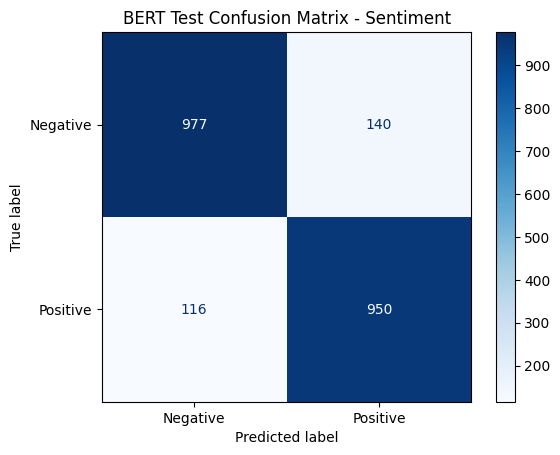

In [16]:
predictions = trainer.predict(tokenized_test)
y_pred = np.argmax(predictions.predictions, axis=1)
y_true = predictions.label_ids

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot(cmap="Blues")
plt.title("BERT Test Confusion Matrix - Sentiment")
plt.show()

## Classification Report - Sentiment

In [17]:
print(classification_report(y_true, y_pred, digits=4, zero_division=0,
                             target_names=["Negative", "Positive"]))

              precision    recall  f1-score   support

    Negative     0.8939    0.8747    0.8842      1117
    Positive     0.8716    0.8912    0.8813      1066

    accuracy                         0.8827      2183
   macro avg     0.8827    0.8829    0.8827      2183
weighted avg     0.8830    0.8827    0.8827      2183



## Saving Sentiment Results

In [18]:
results_df = pd.DataFrame([{
    "model":                "BERT-base",
    "task":                 "Sentiment",
    "validation_macro_f1":  val_results["eval_macro_f1"],
    "test_macro_f1":        test_results["eval_macro_f1"],
    "validation_precision": val_results["eval_precision"],
    "test_precision":       test_results["eval_precision"],
    "validation_recall":    val_results["eval_recall"],
    "test_recall":          test_results["eval_recall"],
    "validation_accuracy":  val_results["eval_accuracy"],
    "test_accuracy":        test_results["eval_accuracy"]
}])

results_path = "results/tables/bert_sentiment_results.csv"
results_df.to_csv(results_path, index=False)

print(f"Saved results to: {results_path}")
results_df

Saved results to: results/tables/bert_sentiment_results.csv


,model,task,validation_macro_f1,test_macro_f1,validation_precision,test_precision,validation_recall,test_recall,validation_accuracy,test_accuracy
0,BERT-base,Sentiment,0.920115,0.882712,0.920096,0.882715,0.920302,0.882923,0.920128,0.88273


## Comparison with Classical Baseline

In [19]:
baseline_df = pd.read_csv("results/tables/baseline_sentiment_results.csv")
bert_df     = pd.read_csv("results/tables/bert_sentiment_results.csv")

comparison_df = pd.concat([baseline_df, bert_df], ignore_index=True)
comparison_df

,model,task,validation_macro_f1,test_macro_f1,validation_precision,test_precision,validation_recall,test_recall,validation_accuracy,test_accuracy
0,TF-IDF + Logistic Regression,Sentiment,0.843348,0.819186,0.843413,0.820016,0.843301,0.818966,NaN,NaN
1,BERT-base,Sentiment,0.920115,0.882712,0.920096,0.882715,0.920302,0.882923,0.920128,0.88273


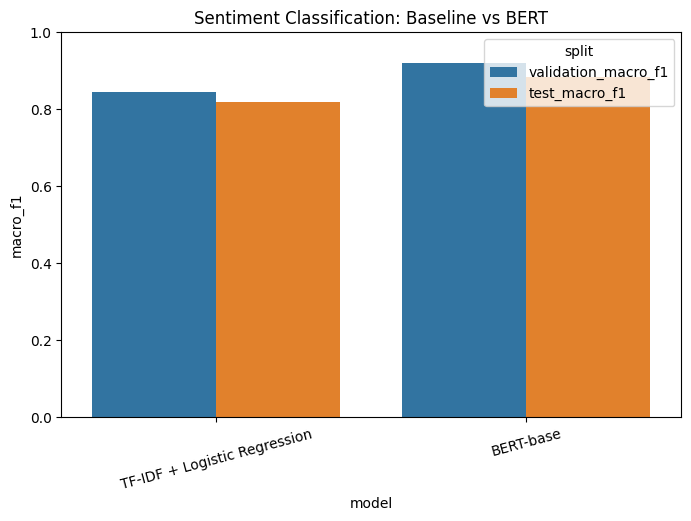

In [20]:
plot_df = comparison_df[["model", "validation_macro_f1", "test_macro_f1"]].copy()
plot_df = plot_df.melt(id_vars="model", var_name="split", value_name="macro_f1")

plt.figure(figsize=(8, 5))
sns.barplot(data=plot_df, x="model", y="macro_f1", hue="split")
plt.title("Sentiment Classification: Baseline vs BERT")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.show()

## Interpretation of Sentiment Results

BERT is evaluated against the TF-IDF baseline to examine whether contextual transformer representations improve performance. Unlike TF-IDF, which relies on surface-level token frequency, BERT uses bidirectional contextual embeddings and is therefore better suited to handling negation, informal expressions, and dialect-specific vocabulary across the UK, Australian, and Indian English varieties present in BESSTIE.

The results show a clear improvement when using the transformer-based approach. The relatively small gap between validation and test performance indicates stable generalisation.

---
# Transformer Modelling: Sarcasm Detection

In this section, BERT-base is fine-tuned on the sarcasm detection task. Sarcasm depends heavily on context and implicit meaning, making it a more suitable task for transformer-based models than for classical TF-IDF baselines.

## Defining Sarcasm Task and Recreating Dataset

In [21]:
LABEL_COL = "Sarcasm"

train_data = train_df[["text", LABEL_COL]].copy()
val_data   = val_df[["text", LABEL_COL]].copy()
test_data  = test_df[["text", LABEL_COL]].copy()

train_data.columns = ["text", "label"]
val_data.columns   = ["text", "label"]
test_data.columns  = ["text", "label"]

train_data["label"] = train_data["label"].astype(int)
val_data["label"]   = val_data["label"].astype(int)
test_data["label"]  = test_data["label"].astype(int)

In [22]:
train_dataset = Dataset.from_pandas(train_data, preserve_index=False)
val_dataset   = Dataset.from_pandas(val_data,   preserve_index=False)
test_dataset  = Dataset.from_pandas(test_data,  preserve_index=False)

print(train_dataset.features)

{'text': Value('large_string'), 'label': Value('int64')}


## Tokenisation

In [23]:
tokenized_train = train_dataset.map(tokenize_function, batched=True)
tokenized_val   = val_dataset.map(tokenize_function,   batched=True)
tokenized_test  = test_dataset.map(tokenize_function,  batched=True)

tokenized_train = tokenized_train.remove_columns(["text"])
tokenized_val   = tokenized_val.remove_columns(["text"])
tokenized_test  = tokenized_test.remove_columns(["text"])

tokenized_train.set_format("torch")
tokenized_val.set_format("torch")
tokenized_test.set_format("torch")

Map: 100%|██████████| 2183/2183 [00:00<00:00, 18220.06 examples/s]


## Model Loading

In [24]:
model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2
)

model.config.problem_type = "single_label_classification"

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 9200.57it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

## Training Arguments

In [25]:
training_args = TrainingArguments(
    output_dir="../results/checkpoints/bert_sarcasm",
    eval_strategy="epoch",
    save_strategy="no",
    logging_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=2,
    weight_decay=0.01,
    load_best_model_at_end=False,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    report_to="none"
)

## Training Model

In [27]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    compute_metrics=compute_metrics
)

trainer.train()

/opt/homebrew/lib/python3.11/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Precision,Recall
1,0.344569,0.327973,0.856230,0.482416,0.597312,0.507646
2,0.251732,0.384490,0.872204,0.678314,0.737939,0.650008


/opt/homebrew/lib/python3.11/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


TrainOutput(global_step=938, training_loss=0.2981505160138551, metrics={'train_runtime': 284.8119, 'train_samples_per_second': 26.312, 'train_steps_per_second': 3.293, 'total_flos': 492938562216960.0, 'train_loss': 0.2981505160138551, 'epoch': 2.0})

## Validation Evaluation

In [28]:
val_results = trainer.evaluate(tokenized_val)
val_results

/opt/homebrew/lib/python3.11/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy,Macro F1,Precision,Recall
0.251732,0.384490,2,0.872204,0.678314,0.737939,0.650008


{'eval_loss': 0.3844901919364929,
 'eval_accuracy': 0.8722044728434505,
 'eval_macro_f1': 0.6783144912641316,
 'eval_precision': 0.7379388903779147,
 'eval_recall': 0.6500084488002703}

## Test Evaluation

In [29]:
test_results = trainer.evaluate(tokenized_test)
test_results

/opt/homebrew/lib/python3.11/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy,Macro F1,Precision,Recall
0.251732,0.407117,2,0.857077,0.642658,0.686784,0.621716


{'eval_loss': 0.4071173667907715,
 'eval_accuracy': 0.8570774163994503,
 'eval_macro_f1': 0.6426583728924538,
 'eval_precision': 0.6867839957990848,
 'eval_recall': 0.6217156374936713}

## Test Confusion Matrix - Sarcasm

/opt/homebrew/lib/python3.11/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


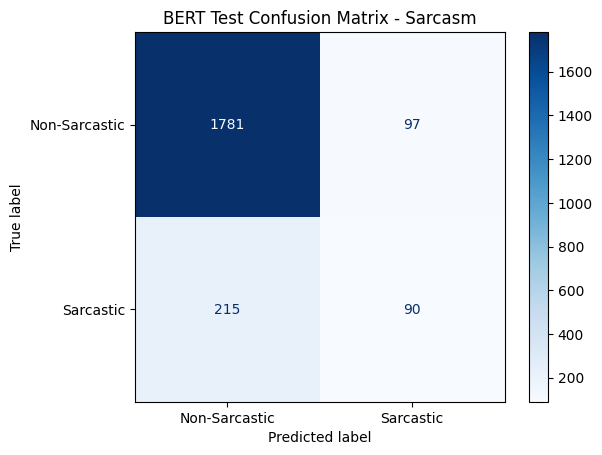

In [30]:
predictions = trainer.predict(tokenized_test)
y_pred = np.argmax(predictions.predictions, axis=1)
y_true = predictions.label_ids

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Sarcastic", "Sarcastic"]
)

disp.plot(cmap="Blues")
plt.title("BERT Test Confusion Matrix - Sarcasm")
plt.show()

## Classification Report - Sarcasm

In [31]:
print(classification_report(y_true, y_pred, digits=4, zero_division=0,
                             target_names=["Non-Sarcastic", "Sarcastic"]))

               precision    recall  f1-score   support

Non-Sarcastic     0.8923    0.9483    0.9195      1878
    Sarcastic     0.4813    0.2951    0.3659       305

     accuracy                         0.8571      2183
    macro avg     0.6868    0.6217    0.6427      2183
 weighted avg     0.8349    0.8571    0.8421      2183



## Saving Sarcasm Results

In [32]:
results_df = pd.DataFrame([{
    "model":                "BERT-base",
    "task":                 "Sarcasm",
    "validation_macro_f1":  val_results["eval_macro_f1"],
    "test_macro_f1":        test_results["eval_macro_f1"],
    "validation_precision": val_results["eval_precision"],
    "test_precision":       test_results["eval_precision"],
    "validation_recall":    val_results["eval_recall"],
    "test_recall":          test_results["eval_recall"],
    "validation_accuracy":  val_results["eval_accuracy"],
    "test_accuracy":        test_results["eval_accuracy"]
}])

results_path = "results/tables/bert_sarcasm_results.csv"
results_df.to_csv(results_path, index=False)

print(f"Saved results to: {results_path}")
results_df

Saved results to: results/tables/bert_sarcasm_results.csv


,model,task,validation_macro_f1,test_macro_f1,validation_precision,test_precision,validation_recall,test_recall,validation_accuracy,test_accuracy
0,BERT-base,Sarcasm,0.678314,0.642658,0.737939,0.686784,0.650008,0.621716,0.872204,0.857077


## Interpretation of Sarcasm Results

BERT is evaluated against the TF-IDF baseline to examine whether contextual transformer representations improve performance on sarcasm detection. Unlike TF-IDF, which relies on surface-level token frequency, BERT uses contextual embeddings and is therefore better suited to handling negation, informal expressions, and implicit meanings such as sarcasm.

The transformer model shows a substantial improvement over the TF-IDF baseline on sarcasm detection. While the TF-IDF model achieves a test Macro-F1 score of approximately 0.46 and fails to detect sarcastic instances effectively, BERT improves performance considerably by capturing contextual and semantic relationships.

The improvement remains limited due to class imbalance, where sarcastic instances are less frequent, making the task inherently challenging even for contextual models.

## Comparison: Baseline vs Transformer Across Tasks

The experimental results reveal a clear distinction between the capabilities of classical and transformer-based models.

For sentiment classification, both models perform relatively well, although BERT provides a noticeable improvement. This is expected, as sentiment is often expressed through explicit lexical cues that can be captured by TF-IDF.

However, for sarcasm detection, the difference is much more pronounced. The TF-IDF model fails to detect sarcastic instances, resulting in a very low Macro-F1 score. In contrast, BERT significantly improves performance by capturing contextual and semantic relationships.

Overall, the results demonstrate that while classical models can serve as strong baselines, transformer-based models provide a more robust and generalisable framework for NLP tasks, particularly those requiring contextual understanding.